# Mach-Zehnder Modulator (MZM) -- $V_\pi$-Defined Push-Pull Design, Meep Baseline, and $\Delta n$ Sweep

This notebook builds and validates a **Mach-Zehnder Modulator**: the active
counterpart to `07_mzi.ipynb`'s passive Mach-Zehnder Interferometer. Both
devices share the same two `coupler.py` 50:50 splitter/combiner stages; where
the MZI creates interference via a fixed geometric path-length difference
$\Delta L$, this device keeps both arms the **same physical length** and
creates a *controllable* phase difference via a push-pull electro-optic index
perturbation $\Delta n(x)$ on both arms.

**The operating point is *defined*, not searched for -- this is a
$\Delta n$-defined ("$\Delta n$-equivalent") $V_\pi$, not a real device's
measured $V_\pi$.** Unlike the coupling
length (`06_directional_coupler.ipynb`, found by sweep + interpolation) or the
MZI's arm-length difference (`07_mzi.ipynb`, found by sweep + selection), this
notebook is handed a target directly: push-pull
$n_\mathrm{upper}=n_\mathrm{core}+\Delta n/2$,
$n_\mathrm{lower}=n_\mathrm{core}-\Delta n/2$, with
$\Delta n_{V_\pi}=0.002$ defined as the point at which the device should
deliver a full $\pi$ phase swing. Section 1 derives the arm length this
implies; Section 10 measures how close the derived length actually lands
to a true $\pi$ swing, and reports the real phase-response factor
rather than forcing agreement with the prior used to size it.

Like every earlier notebook, this one is an educational/validation record,
not just a script -- work through it step by step, and stop at the marked
checkpoints to actually look at the plots before continuing. **Do not use
"Run All."**

**Runtime note**: this device's arm alone is roughly 5x longer than
`07_mzi.ipynb`'s, so its simulation cell is the longest in this toolkit.
It runs at `resolution=25` px/um, coarser than the resolution 40 used for
the standalone coupler and the passive MZI (see Limitations in Section 14).
Sections 4, 5, 9 and 11 run FDTD and take hours on a first run (Section 11's
delay-arm bump also widens the cell); every run is saved to
`si/data/sparams/mzm/` (fields to `si/data/field_cache/`) and reloaded on a re-run
when the recorded parameters match.

## 1. Physical objective

A Mach-Zehnder Modulator converts an electrical drive signal into optical
intensity/phase modulation by shifting one or both interferometer arms'
effective index. In a real device, a voltage reverse-biases a PN junction in
the waveguide core, depleting free carriers and shifting $n_\mathrm{eff}$ via
the plasma-dispersion effect -- typically only $\Delta n\sim10^{-4}$, which is
why real phase-shifter lengths run hundreds of microns to millimeters.

**This notebook does not model that electrical mechanism.** Converting a
drive voltage to a specific $\Delta n$ needs a real carrier-transport
calculation, out of scope here. Everything below works directly
in terms of $\Delta n$, with $\Delta n_{V_\pi}$ standing in for "however large
a $\Delta n$ a real drive voltage would produce."

**Push-pull, not single-arm.** Driving both arms with opposite-sign $\Delta n$
doubles the achievable differential phase for a given $|\Delta n|$ compared to
perturbing one arm alone, directly shortening the phase-shifter length needed
to reach $\pi$.

**Simulation model: 2D effective-index cross-section**, the same convention
`waveguide.py`/`coupler.py`/`mzi.py` use -- `core_index=2.7` is this toolkit's
shared effective index, not bulk silicon's real refractive index (~3.45; see
`09_grating_coupler.ipynb`, the one notebook that resolves the real x-z layer
stack instead). Material is non-dispersive throughout (a constant index
across the analyzed band), same as every other component in this toolkit.

In [1]:
import inspect
import json

import numpy as np
import matplotlib.pyplot as plt
import gdsfactory as gf

from pic_toolkit.meep_sim import mzm
from pic_toolkit import viz, design_points, sweep as sweep_mod, style

style.apply_style()  # shared color palette + plot style for every notebook in this toolkit
%matplotlib inline

# ============================================================
# USER PARAMETERS
# ============================================================
params = dict(mzm.DEFAULT_PARAMS)
params


{'coupling_length_um': 13.848128928800111,
 'gap_um': 0.2,
 'wg_width_um': 0.5,
 'wg_height_um': 0.22,
 'core_index': 2.7,
 'clad_index': 1.44,
 'sbend_len_um': 6.0,
 'wide_sep_um': 2.0,
 'lead_len_um': 2.0,
 'n_seg': 24,
 'mon_size_um': 1.2,
 'margin_um': 0.7,
 'wl_min_um': 1.3,
 'wl_max_um': 1.4,
 'n_freq': 101,
 'wl0_um': 1.35,
 'resolution': 25,
 'dpml_um': 1.0,
 'delta_n_vpi': 0.002,
 'sigma_um': 3.0,
 'margin_sigma': 4.0,
 'phase_factor_prior': 1.02,
 'bump_n_seg': 200,
 'delay_region_len_um': 100.0,
 'delta_L_um': 0.0,
 'dft_decay_tol': 0.001,
 'min_sim_time_factor': 2.0,
 'max_sim_time_factor': 4.0}

### Coupler length used for the splitter/combiner stages

Both stages are `coupler.py`'s directional coupler (gap 200 nm, S-bend 6 µm). This
device uses `coupling_length_um = 13.848` µm, the 50:50 length of the coupler
characterization this MZM was set up with; the current coupler design point
(`06_directional_coupler.ipynb`, resolution 40) is 13.709 µm. The OFF-state
spectrum (Section 6) checks the split directly at this notebook's own
resolution: with both arms identical, any imbalance of the two couplers leaks
power into the bar port, so a bar output far below 1 % confirms that both
stages are close to 50:50.

In [2]:
# Report the coupler length this device uses against the current coupler design point
# (see the markdown above); the split itself is checked by the OFF-state spectrum in Section 6.
coupler_design_point = design_points.load_design_point("../data/design_points/coupler.yaml")
L_design = coupler_design_point["parameters"]["coupling_length_um"]
print(f"coupling_length_um: this device {params['coupling_length_um']:.3f} um, "
      f"coupler design point {L_design:.3f} um (difference {params['coupling_length_um'] - L_design:+.3f} um)")
for key in ["gap_um", "wg_width_um", "sbend_len_um", "wide_sep_um", "core_index", "clad_index"]:
    assert params[key] == coupler_design_point["parameters"][key], key
print("gap, width, S-bend and indices match the coupler design point")


coupling_length_um: this device 13.848 um, coupler design point 13.709 um (difference +0.139 um)
gap, width, S-bend and indices match the coupler design point


### $V_\pi$-derived arm length

$$\pi = \Gamma_\mathrm{eff}\cdot\frac{2\pi}{\lambda_0}\cdot\Delta n_{V_\pi}\cdot L_\mathrm{plateau}
\quad\Longrightarrow\quad
L_\mathrm{plateau} = \frac{\lambda_0}{2\,\Gamma_\mathrm{eff}\,\Delta n_{V_\pi}}$$

$\Gamma_\mathrm{eff}$ is an **effective phase-response factor**
($\Delta n_\mathrm{eff} = \Gamma_\mathrm{eff}\cdot\Delta n_\mathrm{material}$),
not a $0\le\Gamma\le1$ mode-confinement factor -- using `phase_factor_prior`
(see `mzm.DEFAULT_PARAMS`'s comment for where this prior comes from, and why
it's allowed to exceed 1) as the best available estimate for *sizing* the arm --
Section 10 measures the real phase-response factor from an actual Meep run at
this design point and reports it without forcing agreement.

In [3]:
print(inspect.getsource(mzm.plateau_length_um))
print(inspect.getsource(mzm.arm_length_um))

PLATEAU_LENGTH_UM = mzm.plateau_length_um(params)
ARM_LENGTH_UM = mzm.arm_length_um(params)
print(f"\nPLATEAU_LENGTH_UM = {PLATEAU_LENGTH_UM:.1f} um")
print(f"ARM_LENGTH_UM     = {ARM_LENGTH_UM:.1f} um  (plateau + 2*margin_sigma*sigma_um)")


def plateau_length_um(params: dict) -> float:
    """Idealized-then-phase-factor-corrected plateau length for a pi
    push-pull swing at Delta_n = delta_n_vpi:
        pi = Gamma_eff * (2*pi/wl0) * Delta_n * L  =>  L = wl0 / (2*Gamma_eff*Delta_n)
    Gamma_eff (Delta_n_eff = Gamma_eff * Delta_n_material) is an effective
    phase-response factor, NOT a 0<=Gamma<=1 mode-confinement factor -- see
    `phase_factor_prior`'s own DEFAULT_PARAMS comment for why it's allowed to
    exceed 1. Uses phase_factor_prior as the best available estimate for
    sizing -- not re-derived from a measurement in this module itself.
    """
    return params["wl0_um"] / (2.0 * params["phase_factor_prior"] * params["delta_n_vpi"])

def arm_length_um(params: dict) -> float:
    """Total arm length actually built: the phase-active plateau plus an
    inactive erf-ramp margin at each end (see margin_sigma/sigma_um)."""
    return plateau_length_um(params) + 2 * params["margin_sigma"] * params["sigma_um"]


PL

## 2. Build geometry

Both arms extend directly from the coupler stages' own `out_top`/`out_bot`
ports at `wide_sep_um` separation. The push-pull $\Delta n$ overlay
(`mzm.build_index_perturbation`, an erf ramp) is confined to a plateau region
that has already decayed to ~0 well before either coupler stage -- any
leakage there would detune the coupler's carefully-measured 50:50 split.

In [4]:
print(inspect.getsource(mzm.build_index_perturbation))
print(inspect.getsource(mzm.build_geometry))


def build_index_perturbation(x, x1, x2, delta_n_max, sigma):
    """Smooth (erf) Delta_n(x) profile: ~0 outside [x1, x2], ~delta_n_max
    inside, with transition width `sigma` at each edge -- avoids the
    reflection a hard step discontinuity in Delta_n would cause."""
    return 0.5 * delta_n_max * (erf((x - x1) / sigma) - erf((x - x2) / sigma))

def build_geometry(params: dict, delta_n_lower: float = 0.0, delta_n_upper: float = 0.0) -> list:
    """Two coupler stages (splitter, combiner), each coupler.build_geometry's
    own validated 50:50 shape translated into place, joined by two arms of
    IDENTICAL physical length extending directly from the coupler ports' own
    wide_sep_um separation: the top arm carries delta_n_upper, the bottom arm
    carries delta_n_lower, each as an erf-ramped overlay (build_index_
    perturbation) confined to the plateau region (px1, px2) -- ~0 by
    construction at either coupler stage. When delta_L_um > 0, the bottom arm
    additionally carries

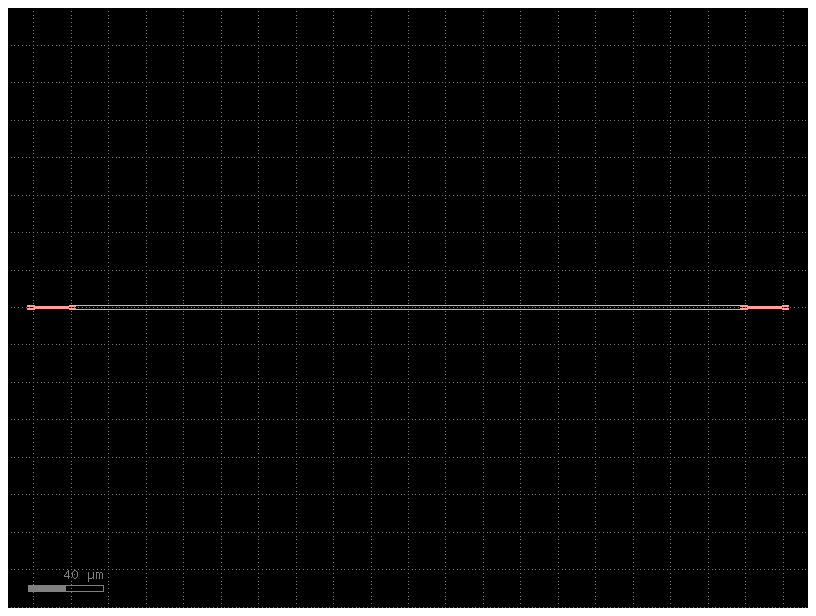

In [5]:
gf_component = mzm.build_gf_component(params)
fig = gf_component.plot()
plt.show()

## 3. Permittivity map

Native (`mp.Medium`-function) vs. gdsfactory-derived geometry, same
native-vs-gds diff discipline every earlier notebook follows -- though only the native path can show the real $\Delta n(x)$
overlay at all, since gdsfactory has no notion of a spatially-varying index.
Shown here at the $V_\pi$ push-pull-ON operating point.

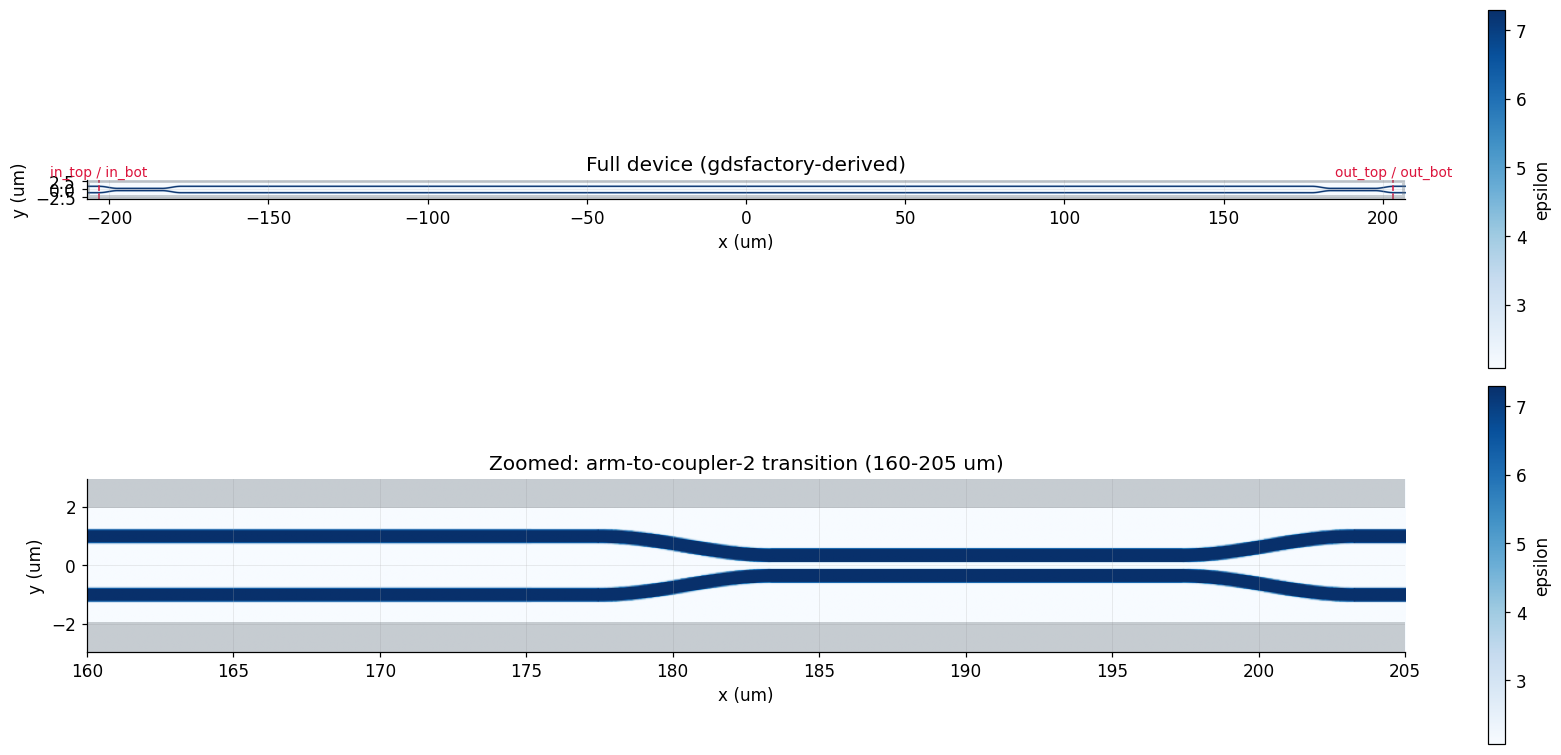

In [6]:
DN_LOWER_ON = -params["delta_n_vpi"] / 2
DN_UPPER_ON = params["delta_n_vpi"] / 2

perm_map = mzm.get_permittivity_map(params, DN_LOWER_ON, DN_UPPER_ON, use_native_geometry=False)
ports = mzm._ports(params)
port_marks = [
    (ports["in_top"].x, 0, "in_top / in_bot", "v"),
    (ports["out_top"].x, 0, "out_top / out_bot", "v"),
]

fig, (ax_full, ax_zoom) = plt.subplots(2, 1, figsize=(16, 7))
viz.plot_permittivity(perm_map.eps, perm_map.extent_um, ax=ax_full, pml_um=params["dpml_um"], ports=port_marks)
ax_full.set_title("Full device (gdsfactory-derived)")
viz.plot_permittivity(perm_map.eps, perm_map.extent_um, ax=ax_zoom, pml_um=params["dpml_um"])
ax_zoom.set_xlim(160, 205)
ax_zoom.set_title("Zoomed: arm-to-coupler-2 transition (160-205 um)")
fig.tight_layout()
plt.show()


native vs. gdsfactory permittivity diff: max=2.334  mean=0.03105  fraction of pixels differing by >0.01 = 4.9836%


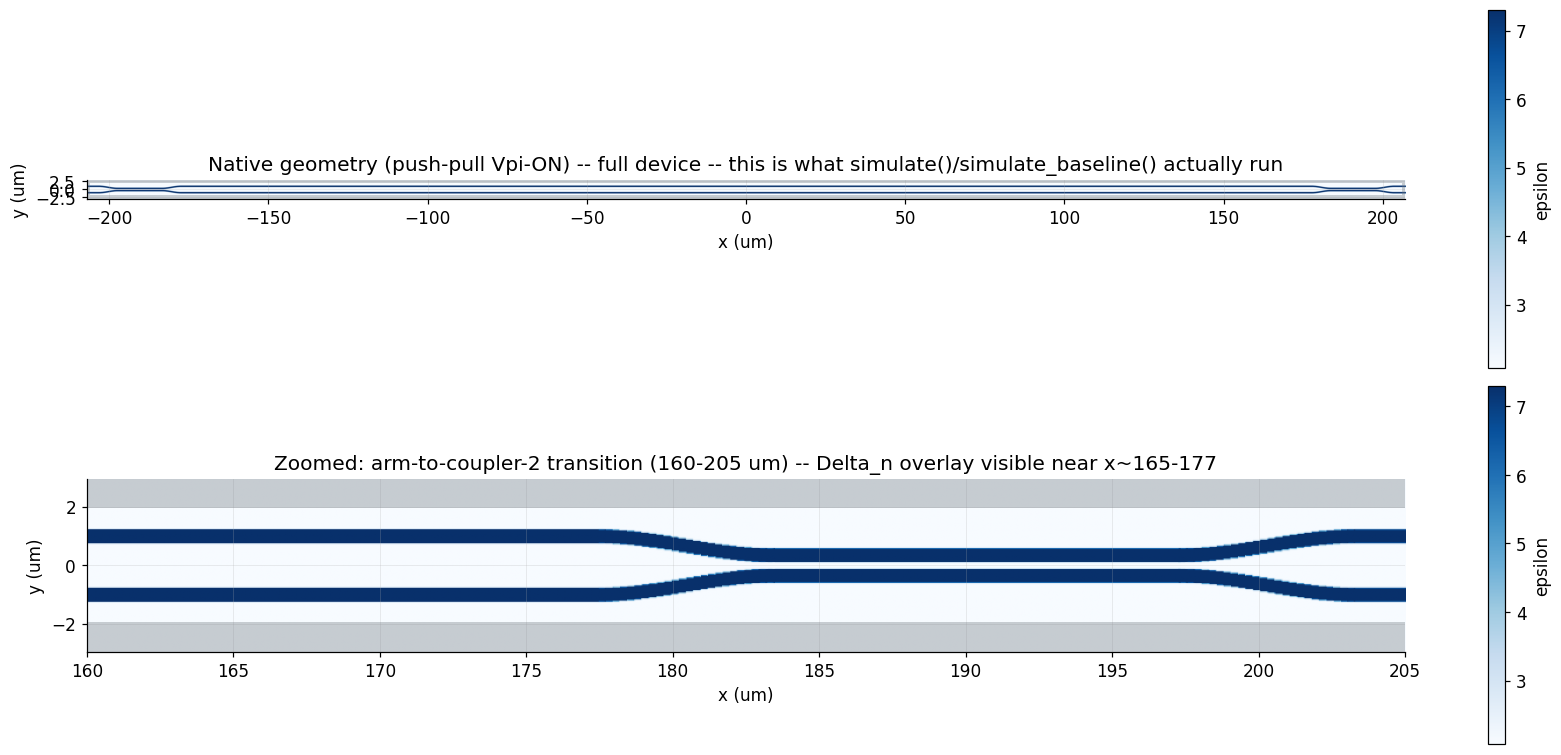

In [7]:
perm_map_native = mzm.get_permittivity_map(params, DN_LOWER_ON, DN_UPPER_ON, use_native_geometry=True)
diff = np.abs(perm_map_native.eps - perm_map.eps)
print(f"native vs. gdsfactory permittivity diff: max={diff.max():.3f}  mean={diff.mean():.5f}  "
      f"fraction of pixels differing by >0.01 = {(diff > 0.01).mean():.4%}")

fig, (ax_full, ax_zoom) = plt.subplots(2, 1, figsize=(16, 7))
viz.plot_permittivity(perm_map_native.eps, perm_map_native.extent_um, ax=ax_full, pml_um=params["dpml_um"])
ax_full.set_title("Native geometry (push-pull Vpi-ON) -- full device -- this is what simulate()/simulate_baseline() actually run")
viz.plot_permittivity(perm_map_native.eps, perm_map_native.extent_um, ax=ax_zoom, pml_um=params["dpml_um"])
ax_zoom.set_xlim(160, 205)
ax_zoom.set_title("Zoomed: arm-to-coupler-2 transition (160-205 um) -- Delta_n overlay visible near x~165-177")
fig.tight_layout()
plt.show()


> **STOP -- INSPECT THE PERMITTIVITY MAP BEFORE RUNNING FDTD.** Confirm
> both coupler stages look like `06_directional_coupler.ipynb`'s own
> validated geometry, and that the arm looks like a single straight
> waveguide (the $\Delta n$ overlay is a real-valued index perturbation, not
> a visible structural change in permittivity at this color scale).

## 4. Baseline FDTD simulation

Full 4-port characterization at the $V_\pi$ push-pull-ON operating point:
excite `in_top` **and** `in_bot` independently, enabling a genuine
Lorentz-reciprocity check ($S_{21}$ vs $S_{12}$) -- the same discipline
`07_mzi.ipynb`'s own baseline follows. This is the one operating point this
notebook validates at full (strict-tolerance) rigor.

> **STOP -- this is the slowest single cell in the notebook (two full FDTD
> runs on this device's long domain).**

In [8]:
print(inspect.getsource(mzm.simulate_baseline))


def simulate_baseline(params: dict | None = None, delta_n_lower: float | None = None,
                       delta_n_upper: float | None = None) -> MZMResult:
    """Full 4-port characterization at the canonical push-pull-ON operating
    point (default: delta_n_lower=-delta_n_vpi/2, delta_n_upper=+delta_n_vpi/2,
    i.e. the Vpi design point itself): excite in_top (port 1) AND in_bot
    (port 2) independently, enabling a genuine Lorentz-reciprocity check
    (S21 vs S12) the same way mzi.py's own baseline does. This is the one
    operating point this module validates at full (strict-tolerance) rigor;
    the Delta_n sweep and delta_L_um check (Sections 9/11) use the cheaper
    single-excitation `simulate` instead.
    """
    params = {**DEFAULT_PARAMS, **(params or {})}
    if delta_n_lower is None:
        delta_n_lower = -params["delta_n_vpi"] / 2
    if delta_n_upper is None:
        delta_n_upper = params["delta_n_vpi"] / 2

    freqs, inc1, refl1, cross1, top1, bot1, field_sn

In [9]:
# Dual-excitation FDTD at the V_pi push-pull point, or the saved result of an identical run
# (load_or_simulate checks every recorded parameter, the push-pull point and n_freq).
result = mzm.load_or_simulate(params, DN_LOWER_ON, DN_UPPER_ON, "../data/sparams/mzm/baseline/mzm_baseline",
                              dual_excitation=True)
print("wavelengths (um):", result.wavelengths_um.min(), "-", result.wavelengths_um.max())


loaded cached FDTD result: ../data/sparams/mzm/baseline/mzm_baseline
wavelengths (um): 1.301721854304636 - 1.4019971469329529


## 5. Electromagnetic field visualization -- polarization convention

`eig_parity=mp.TE` is forced at every source/monitor (`NO_PARITY` would select TM); the
DFT field capture records whichever of $E_z$/$H_z$ actually dominates rather
than assuming either, same convention `coupler.py` already established.

loaded cached result: ../data/field_cache/mzm_vpi_snapshot.pkl


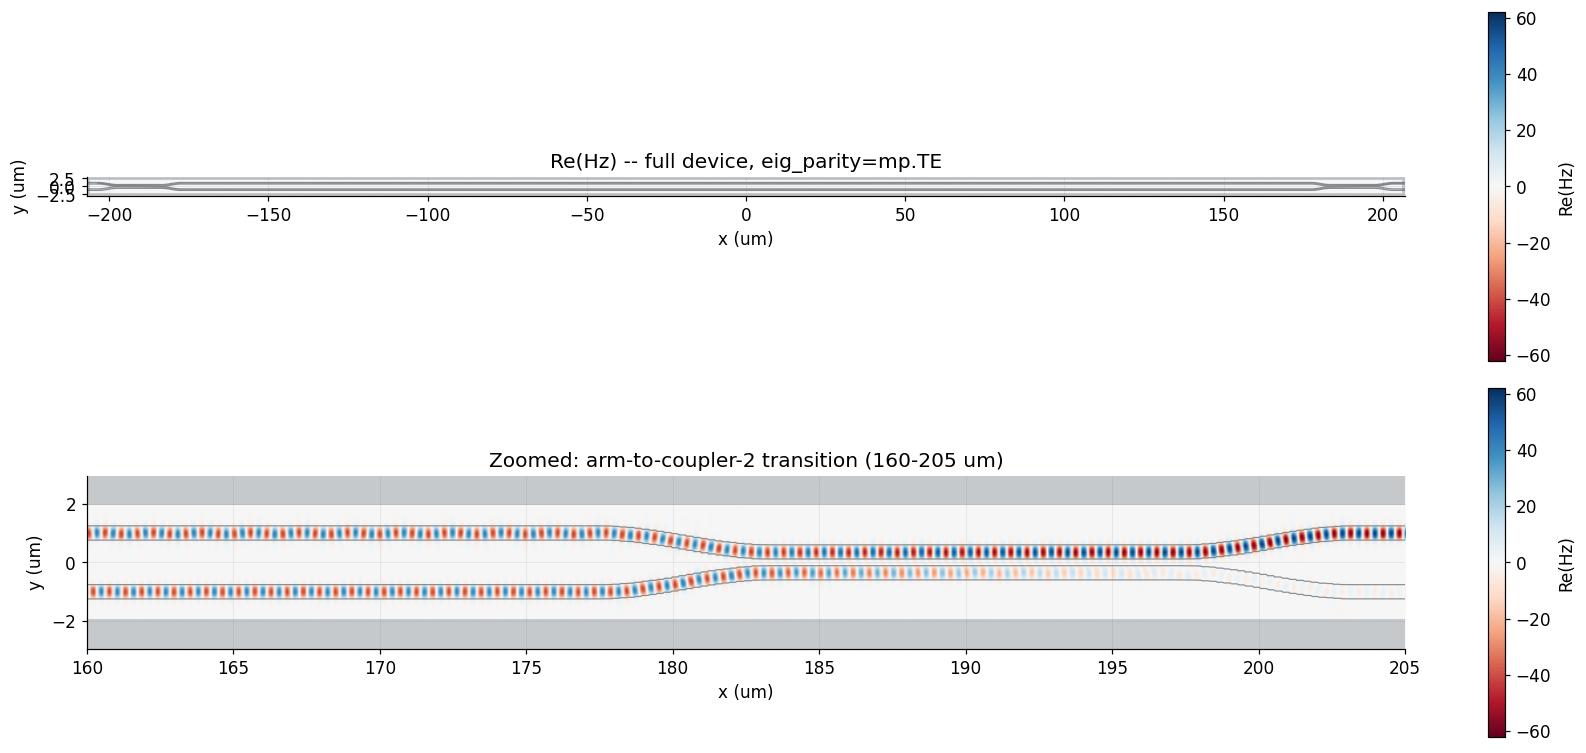

dominant field component: Hz


In [10]:
# Field of a single in_top excitation at the same V_pi push-pull point (simulate_baseline's
# results do not keep the raw field array), cached in si/data/field_cache/.
snap = mzm.load_or_capture_field_snapshot(params, DN_LOWER_ON, DN_UPPER_ON,
                                          "../data/field_cache/mzm_vpi_snapshot.pkl")

fig, (ax_full, ax_zoom) = plt.subplots(2, 1, figsize=(16, 7))
viz.plot_field(snap.field, snap.eps, snap.extent_um, component=snap.component, ax=ax_full, pml_um=params["dpml_um"])
ax_full.set_title(f"Re({snap.component}) -- full device, eig_parity=mp.TE")
viz.plot_field(snap.field, snap.eps, snap.extent_um, component=snap.component, ax=ax_zoom, pml_um=params["dpml_um"])
ax_zoom.set_xlim(160, 205)
ax_zoom.set_title("Zoomed: arm-to-coupler-2 transition (160-205 um)")
fig.tight_layout()
plt.show()
print(f"dominant field component: {snap.component}")


> **STOP -- INSPECT THE ELECTROMAGNETIC FIELD BEFORE CONTINUING.** Confirm
> the input mode splits at the first coupler, propagates down both arms, and
> recombines at the second coupler -- and that `Hz` (not `Ez`) dominates,
> confirming genuine TE propagation.

## 6. Transmission and phase spectra

Port convention (matching `07_mzi.ipynb`): port 1 = `in_top`, port 2 =
`in_bot`, port 3 = `out_top`, port 4 = `out_bot`. $S_{31}$/$S_{41}$ are the
through ("bar")/cross response to a port-1 excitation.

Shown below for **both** the $V_\pi$-ON push-pull state (this notebook's baseline, Section 4) and the unperturbed OFF state ($\Delta n=0$, reused from Section 9's sweep rather than re-simulated) side by side, so the modulation itself is visible directly in the spectra rather than only as a single-wavelength number.

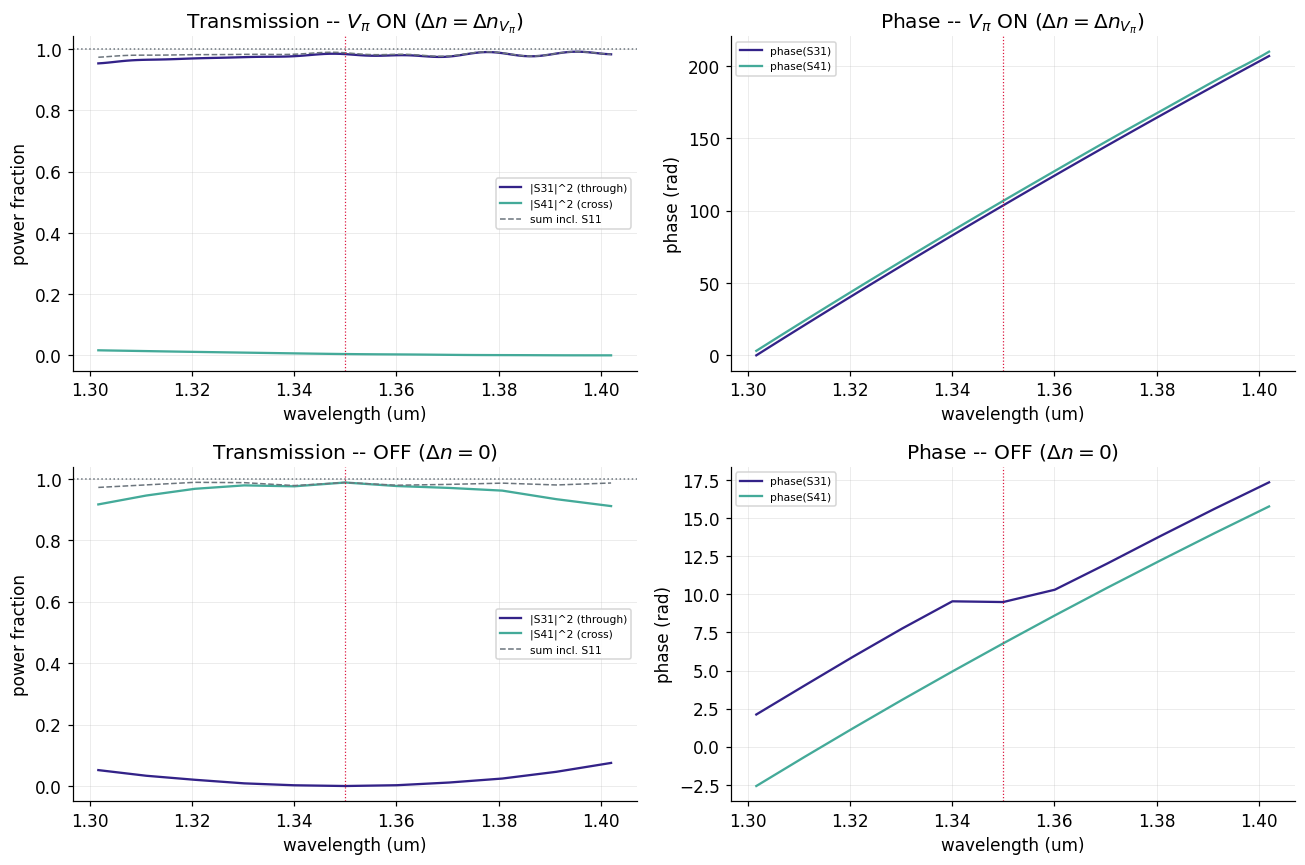

ON  @ wl0=1.35 um: |S31|^2=0.9833  |S41|^2=0.0042  |S11|^2=0.0001
OFF @ wl0=1.35 um: |S31|^2=0.0000  |S41|^2=0.9882  |S11|^2=0.0001


In [11]:
baseline_artifact = mzm.load_artifact("../data/sparams/mzm/baseline/mzm_baseline")
off_artifact = mzm.load_artifact("../data/sparams/mzm/sweep/mzm_dn0p0000")
# NOTE: off_artifact comes from Section 9's delta_n sweep (n_freq=11, coarser than the
# baseline's own n_freq=101) -- reused rather than re-simulated at full resolution, since a
# second full dual-excitation OFF-state baseline would cost as much as the ON-state one did.

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
(ax_mag_on, ax_phase_on), (ax_mag_off, ax_phase_off) = axes

for ax_mag, ax_phase, art, label in [
    (ax_mag_on, ax_phase_on, baseline_artifact, r"$V_\pi$ ON ($\Delta n=\Delta n_{V_\pi}$)"),
    (ax_mag_off, ax_phase_off, off_artifact, r"OFF ($\Delta n=0$)"),
]:
    wl = art.wavelengths_um
    order = np.argsort(wl)
    wl_s, S31_s, S41_s, S11_s = wl[order], art.S31[order], art.S41[order], art.S11[order]

    ax_mag.plot(wl_s, np.abs(S31_s) ** 2, color=style.COLOR_CYCLE[0], label="|S31|^2 (through)")
    ax_mag.plot(wl_s, np.abs(S41_s) ** 2, color=style.COLOR_CYCLE[2], label="|S41|^2 (cross)")
    ax_mag.plot(wl_s, np.abs(S31_s) ** 2 + np.abs(S41_s) ** 2 + np.abs(S11_s) ** 2,
                "--", color=style.COLOR_REFERENCE, lw=1, label="sum incl. S11")
    ax_mag.axhline(1.0, color=style.COLOR_REFERENCE, ls=":", lw=1)
    ax_mag.axvline(params["wl0_um"], color=style.COLOR_ANNOTATION, lw=0.8, ls=":")
    ax_mag.set_xlabel("wavelength (um)"); ax_mag.set_ylabel("power fraction")
    ax_mag.set_title(f"Transmission -- {label}"); ax_mag.legend(fontsize=7)

    ax_phase.plot(wl_s, np.unwrap(np.angle(S31_s)), color=style.COLOR_CYCLE[0], label="phase(S31)")
    ax_phase.plot(wl_s, np.unwrap(np.angle(S41_s)), color=style.COLOR_CYCLE[2], label="phase(S41)")
    ax_phase.axvline(params["wl0_um"], color=style.COLOR_ANNOTATION, lw=0.8, ls=":")
    ax_phase.set_xlabel("wavelength (um)"); ax_phase.set_ylabel("phase (rad)")
    ax_phase.set_title(f"Phase -- {label}"); ax_phase.legend(fontsize=7)

fig.tight_layout()
plt.show()

i0_on = np.argmin(np.abs(baseline_artifact.wavelengths_um - params["wl0_um"]))
i0_off = np.argmin(np.abs(off_artifact.wavelengths_um - params["wl0_um"]))
print(f"ON  @ wl0={params['wl0_um']} um: |S31|^2={np.abs(baseline_artifact.S31[i0_on])**2:.4f}  "
      f"|S41|^2={np.abs(baseline_artifact.S41[i0_on])**2:.4f}  |S11|^2={np.abs(baseline_artifact.S11[i0_on])**2:.4f}")
print(f"OFF @ wl0={params['wl0_um']} um: |S31|^2={np.abs(off_artifact.S31[i0_off])**2:.4f}  "
      f"|S41|^2={np.abs(off_artifact.S41[i0_off])**2:.4f}  |S11|^2={np.abs(off_artifact.S11[i0_off])**2:.4f}")


## 7. Physics sanity checks

Tolerances start from `07_mzi.ipynb`'s own already-measured values (the
closest precedent: another long-domain, two-coupler-stage device) since this
is a new component with no prior measurement of its own -- measure first:
these may need loosening once the actual
deviation below is known; do not tighten them below what is actually
observed.

In [12]:
ENERGY_TOL = 0.08          # starting point: 07_mzi.ipynb's own measured worst case was ~0.074
RECIPROCITY_TOL = 0.05
PASSIVITY_TOL = 0.01
MAX_EXPECTED_LOSS = 0.08

validation = mzm.run_all_checks(result, energy_tol=ENERGY_TOL, reciprocity_tol=RECIPROCITY_TOL,
                                 passivity_tol=PASSIVITY_TOL, max_expected_loss=MAX_EXPECTED_LOSS)
print(json.dumps(validation, indent=2))
assert validation["passed"], "Baseline failed sanity checks -- do not save or use this result."


{
  "energy_conservation": {
    "max_deviation_port1": 0.0,
    "max_deviation_port2": 0.0,
    "max_deviation": 0.0,
    "max_expected_loss": 0.08,
    "tolerance": 0.08,
    "passed": true
  },
  "reciprocity": {
    "max_diff": 0.00013751502761790316,
    "tolerance": 0.05,
    "passed": true
  },
  "passivity": {
    "max_power_fraction": 0.9913452849432075,
    "tolerance": 0.01,
    "passed": true
  },
  "passed": true
}


## 8. Save baseline artifact

In [13]:
artifact_stem = "../data/sparams/mzm/baseline/mzm_baseline"
metadata = {
    "component": "mzm",
    "geometry_params": {k: v for k, v in params.items() if k.endswith("_um")},
    "material_params": {k: params[k] for k in ["core_index", "clad_index"]},
    "polarization": "TE (forced via eig_parity=mp.TE)",
    "meep_resolution": params["resolution"],
    "simulation_params": params,
    "delta_n_vpi": params["delta_n_vpi"],
    "arm_length_um": ARM_LENGTH_UM, "plateau_length_um": PLATEAU_LENGTH_UM,
    "meep_version": result.sim_params["meep_version"],
    "python_version": result.sim_params["python_version"],
    "creation_date": result.sim_params["creation_date"],
    "validation": validation,
}
mzm.save_artifact(artifact_stem, result, metadata)
print("saved:", artifact_stem)


saved: ../data/sparams/mzm/baseline/mzm_baseline


---
## 9. $\Delta n$ sweep -- does the device actually modulate?

With `delta_L_um=0` (no static bias), sweeping the push-pull $\Delta n$ from 0
to $\Delta n_{V_\pi}$ should carry the device from $|S_{41}|^2\approx1$ (arms
identical, all power crosses) to as close to $|S_{31}|^2\approx1$ as this
design's real phase-response factor $\Gamma_\mathrm{eff}$ (Section 10) allows.
Each point uses the cheaper
single-excitation `mzm.simulate` (not `simulate_baseline`) -- a full
dual-excitation reciprocity check at every sweep point would be prohibitively
expensive on this device's domain.

> **STOP -- the cell below runs 5 full FDTD simulations back to back on a first run
> (saved results with the same parameters are reloaded instead).**

In [14]:
DELTA_N_SWEEP = [0.0, 0.0005, 0.0010, 0.0015, params["delta_n_vpi"]]
SWEEP_N_FREQ = 11   # fewer than the baseline's 101 -- FDTD cost is timestep-dominated, not
                    # DFT-point-dominated, so this only trims memory/postprocessing across
                    # 5 back-to-back runs on an already-long domain.

sweep_results = {}
sweep_rows = []
for dn in DELTA_N_SWEEP:
    run_params = {**params, "n_freq": SWEEP_N_FREQ}
    tag = f"dn{dn:.4f}".replace(".", "p")
    artifact_stem = f"../data/sparams/mzm/sweep/mzm_{tag}"
    res = mzm.load_or_simulate(run_params, -dn / 2, dn / 2, artifact_stem)
    sweep_results[dn] = res
    i0 = np.argmin(np.abs(res.wavelengths_um - params["wl0_um"]))
    t31, t41 = np.abs(res.S31[i0]) ** 2, np.abs(res.S41[i0]) ** 2
    print(f"  delta_n={dn:.4f}  ->  |S31|^2={t31:.4f}  |S41|^2={t41:.4f}  |S11|^2={np.abs(res.S11[i0])**2:.4f}")

    mzm.save_artifact(artifact_stem, res, {
        "component": "mzm", "swept_param": "delta_n", "delta_n": dn, "simulation_params": run_params,
        "meep_resolution": run_params["resolution"], "meep_version": res.sim_params["meep_version"],
        "creation_date": res.sim_params["creation_date"],
    })
    sweep_rows.append({"delta_n": dn, "T_through": t31, "T_cross": t41,
                        "artifact_path": artifact_stem})

sweep_mod.save_manifest(sweep_rows, "../data/sparams/mzm/sweep/manifest.csv")


loaded cached FDTD result: ../data/sparams/mzm/sweep/mzm_dn0p0000
  delta_n=0.0000  ->  |S31|^2=0.0000  |S41|^2=0.9882  |S11|^2=0.0001
loaded cached FDTD result: ../data/sparams/mzm/sweep/mzm_dn0p0005
  delta_n=0.0005  ->  |S31|^2=0.1544  |S41|^2=0.8311  |S11|^2=0.0001
loaded cached FDTD result: ../data/sparams/mzm/sweep/mzm_dn0p0010
  delta_n=0.0010  ->  |S31|^2=0.5235  |S41|^2=0.4612  |S11|^2=0.0001
loaded cached FDTD result: ../data/sparams/mzm/sweep/mzm_dn0p0015
  delta_n=0.0015  ->  |S31|^2=0.8738  |S41|^2=0.1120  |S11|^2=0.0001
loaded cached FDTD result: ../data/sparams/mzm/sweep/mzm_dn0p0020
  delta_n=0.0020  ->  |S31|^2=0.9833  |S41|^2=0.0042  |S11|^2=0.0001


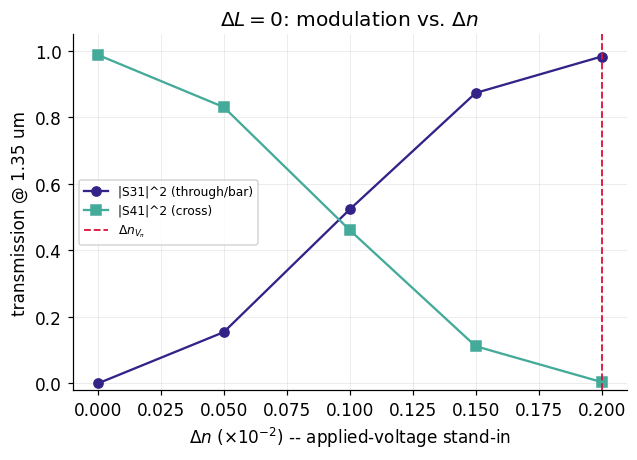

In [15]:
dn_arr = np.array(DELTA_N_SWEEP)
T_through_vs_dn, T_cross_vs_dn = [], []
for dn in DELTA_N_SWEEP:
    res = sweep_results[dn]
    i0 = np.argmin(np.abs(res.wavelengths_um - params["wl0_um"]))
    T_through_vs_dn.append(np.abs(res.S31[i0]) ** 2)
    T_cross_vs_dn.append(np.abs(res.S41[i0]) ** 2)
T_through_vs_dn, T_cross_vs_dn = np.array(T_through_vs_dn), np.array(T_cross_vs_dn)

DN_SCALE = 100   # plot Delta_n in units of 1e-2 -- the raw values (0.0000, 0.0005, 0.0010, ...)
                 # overlap as x-tick labels at this precision; x1e2 gives short, legible ticks
                 # (0.0, 0.5, 1.0, ...) without losing any information.
dn_scaled = dn_arr * DN_SCALE

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(dn_scaled, T_through_vs_dn, "o-", color=style.COLOR_CYCLE[0], label="|S31|^2 (through/bar)")
ax.plot(dn_scaled, T_cross_vs_dn, "s-", color=style.COLOR_CYCLE[2], label="|S41|^2 (cross)")
ax.axvline(params["delta_n_vpi"] * DN_SCALE, color=style.COLOR_ANNOTATION, lw=1.2, ls="--",
           label=r"$\Delta n_{V_\pi}$")
ax.set_xlabel(r"$\Delta n$ ($\times 10^{-2}$) -- applied-voltage stand-in")
ax.set_ylabel(f"transmission @ {params['wl0_um']} um"); ax.set_ylim(-0.02, 1.05)
ax.set_title(r"$\Delta L=0$: modulation vs. $\Delta n$")
ax.legend(fontsize=8)
plt.show()


## 10. Confirming the $V_\pi$ design point

The differential phase $\Delta\phi$ is read from the two outputs at $\lambda_0$ for every
sweep point. The bar fraction $T_\mathrm{bar}=|S_{31}|^2/(|S_{31}|^2+|S_{41}|^2)$ gives
$\sin^2(\Delta\phi/2)$, normalized by the total output so the small excess loss does not
bias the inversion. $T_\mathrm{bar}$ alone cannot distinguish $\Delta\phi$ from
$2\pi-\Delta\phi$; the complex ratio $S_{31}/S_{41}$ can. For two identical couplers it is
proportional to $\tan(\Delta\phi/2)$, so its phase jumps by $\pi$ when $\Delta\phi$
passes $\pi$. Each point then gives a phase-response factor
$\Gamma_\mathrm{eff}=\Delta\phi/(k_0\,\Delta n\,L_\mathrm{plateau})$; a constant value across
the sweep confirms that the phase is linear in $\Delta n$. The measured value is reported
as it is, without forcing agreement with `phase_factor_prior` (only a sizing estimate).

In [16]:
# Differential phase at wl0 for every sweep point (see the markdown above): invert the
# normalized bar fraction, and take the branch beyond pi wherever arg(S31/S41) has flipped
# relative to the first driven point (whose phase is well below pi).
K0 = 2 * np.pi / params["wl0_um"]

def outputs_at_wl0(res):
    i0 = np.argmin(np.abs(res.wavelengths_um - params["wl0_um"]))
    return res.S31[i0], res.S41[i0]

ref_ratio_phase = np.angle(np.divide(*outputs_at_wl0(sweep_results[DELTA_N_SWEEP[1]])))
dphi_vs_dn = []
print("  delta_n   T_bar(norm)  arg(S31/S41)/pi   dphi/pi   Gamma_eff")
for dn in DELTA_N_SWEEP:
    s31, s41 = outputs_at_wl0(sweep_results[dn])
    t_bar = abs(s31) ** 2 / (abs(s31) ** 2 + abs(s41) ** 2)
    theta = 2 * np.arcsin(np.sqrt(t_bar))
    if dn == 0:
        dphi = 0.0   # identical arms; arg(S31/S41) is undefined when S31 ~ 0
        print(f"  {dn:.4f}    {t_bar:.4f}           --           {dphi/np.pi:.3f}       --")
    else:
        flipped = np.cos(np.angle(s31 / s41) - ref_ratio_phase) < 0
        dphi = 2 * np.pi - theta if flipped else theta
        gamma = dphi / (K0 * dn * PLATEAU_LENGTH_UM)
        print(f"  {dn:.4f}    {t_bar:.4f}       {np.angle(s31 / s41)/np.pi:+.3f}         {dphi/np.pi:.3f}     {gamma:.3f}")
    dphi_vs_dn.append(dphi)
dphi_vs_dn = np.array(dphi_vs_dn)

DPHI_MEEP_VPI = dphi_vs_dn[-1]
PHASE_FACTOR_MEASURED = DPHI_MEEP_VPI / (K0 * params["delta_n_vpi"] * PLATEAU_LENGTH_UM)
slope = np.sum(dphi_vs_dn * dn_arr) / np.sum(dn_arr ** 2)   # least-squares line through the origin
print(f"\nphase at Delta_n_Vpi = {DPHI_MEEP_VPI/np.pi:.3f} pi (target 1.000 pi); "
      f"linear fit over the sweep gives {slope * params['delta_n_vpi'] / np.pi:.3f} pi")
print(f"measured phase-response factor Gamma_eff = {PHASE_FACTOR_MEASURED:.3f} "
      f"(prior used for sizing: {params['phase_factor_prior']})")


  delta_n   T_bar(norm)  arg(S31/S41)/pi   dphi/pi   Gamma_eff
  0.0000    0.0000           --           0.000       --
  0.0005    0.1567       +0.000         0.259     1.057
  0.0010    0.5316       +0.000         0.520     1.061
  0.0015    0.8864       +0.001         0.781     1.062
  0.0020    0.9957       +0.999         1.042     1.063

phase at Delta_n_Vpi = 1.042 pi (target 1.000 pi); linear fit over the sweep gives 1.041 pi
measured phase-response factor Gamma_eff = 1.063 (prior used for sizing: 1.02)


## 11. Path-length bias check -- does $S_{31}/S_{41}$ still switch at $\Delta L=10\ \mathrm{\mu m}$?

Combining this device's push-pull $\Delta n$ with `mzi.py`'s own geometric
path-length-difference technique (`delta_L_um`): a fixed static phase bias is
added to one arm via a raised-cosine bump (reused directly from `mzi.py`,
not re-implemented -- see `meep_sim/mzm.py`'s module docstring for why an
axis-aligned-Block reimplementation of this bend was tried and rejected
elsewhere). Running at $\Delta n=0$ and $\Delta n=\Delta n_{V_\pi}$ shows
whether the same push-pull drive still flips the device between bar and
cross once that static bias is present.

> **STOP -- this cell runs 2 more full FDTD simulations on a first run, on a device whose
> delay-arm bump also widens the transverse cell size (see
> `mzm._compute_domain`) -- individually more expensive than Section 9's own
> runs.**

Unlike Section 6's $\Delta L=0$ case, a nonzero $\Delta L$ adds a fixed geometric phase that depends on wavelength, so the device's response is no longer flat/symmetric across the band -- Section 11 below therefore plots the full spectrum (power and phase) for both $\Delta n$ states, the same 2x2 layout as Section 6, rather than reading out a single wavelength. At $\Delta n=0$ this should reduce to `07_mzi.ipynb`'s own passive-MZI result (same $\Delta L$ mechanism, no active perturbation); switching to $\Delta n=V_\pi$ should swap which of $S_{31}$/$S_{41}$ dominates. Both spectra below use the same  coarse sampling as Section 9 (reused artifacts, not re-simulated at finer resolution), so the fringes appear as straight-line segments between sample points rather than smooth curves -- the FSR-like periodicity and the bar/cross swap are still clearly visible at this sampling density.

In [17]:
DELTA_N_SWEEP_DL = [0.0, params["delta_n_vpi"]]
DELTA_L_UM = 10.0
DL_N_FREQ = SWEEP_N_FREQ * 3   # ~3x Section 9's sweep resolution -- delta_L_um>0 introduces a
                                # real wavelength dependence (a static geometric phase bias, on
                                # top of the push-pull Delta_n), so resolving its fringe pattern
                                # needs more than Section 9's flat-response-appropriate 11 points.
params_dl = {**params, "delta_L_um": DELTA_L_UM, "n_freq": DL_N_FREQ}

dl_results = {}
dl_rows = []
for dn in DELTA_N_SWEEP_DL:
    tag = f"dn{dn:.4f}".replace(".", "p")
    artifact_stem = f"../data/sparams/mzm/delta_L/mzm_dL{DELTA_L_UM:.0f}_{tag}"
    res = mzm.load_or_simulate(params_dl, -dn / 2, dn / 2, artifact_stem)
    dl_results[dn] = res
    i0 = np.argmin(np.abs(res.wavelengths_um - params["wl0_um"]))
    t31, t41, t11 = np.abs(res.S31[i0]) ** 2, np.abs(res.S41[i0]) ** 2, np.abs(res.S11[i0]) ** 2
    print(f"  delta_L={DELTA_L_UM}um, delta_n={dn:.4f}  ->  |S31|^2={t31:.4f}  |S41|^2={t41:.4f}  "
          f"|S11|^2={t11:.4f}  sum={t31+t41+t11:.4f}")

    mzm.save_artifact(artifact_stem, res, {
        "component": "mzm", "delta_L_um": DELTA_L_UM, "delta_n": dn, "simulation_params": params_dl,
        "meep_resolution": params_dl["resolution"], "meep_version": res.sim_params["meep_version"],
        "creation_date": res.sim_params["creation_date"],
    })
    dl_rows.append({"delta_L_um": DELTA_L_UM, "delta_n": dn, "T_through": t31, "T_cross": t41,
                     "artifact_path": artifact_stem})

sweep_mod.save_manifest(dl_rows, "../data/sparams/mzm/delta_L/manifest.csv")


loaded cached FDTD result: ../data/sparams/mzm/delta_L/mzm_dL10_dn0p0000
  delta_L=10.0um, delta_n=0.0000  ->  |S31|^2=0.1309  |S41|^2=0.8304  |S11|^2=0.0002  sum=0.9615
loaded cached FDTD result: ../data/sparams/mzm/delta_L/mzm_dL10_dn0p0020
  delta_L=10.0um, delta_n=0.0020  ->  |S31|^2=0.5139  |S41|^2=0.4233  |S11|^2=0.0000  sum=0.9372


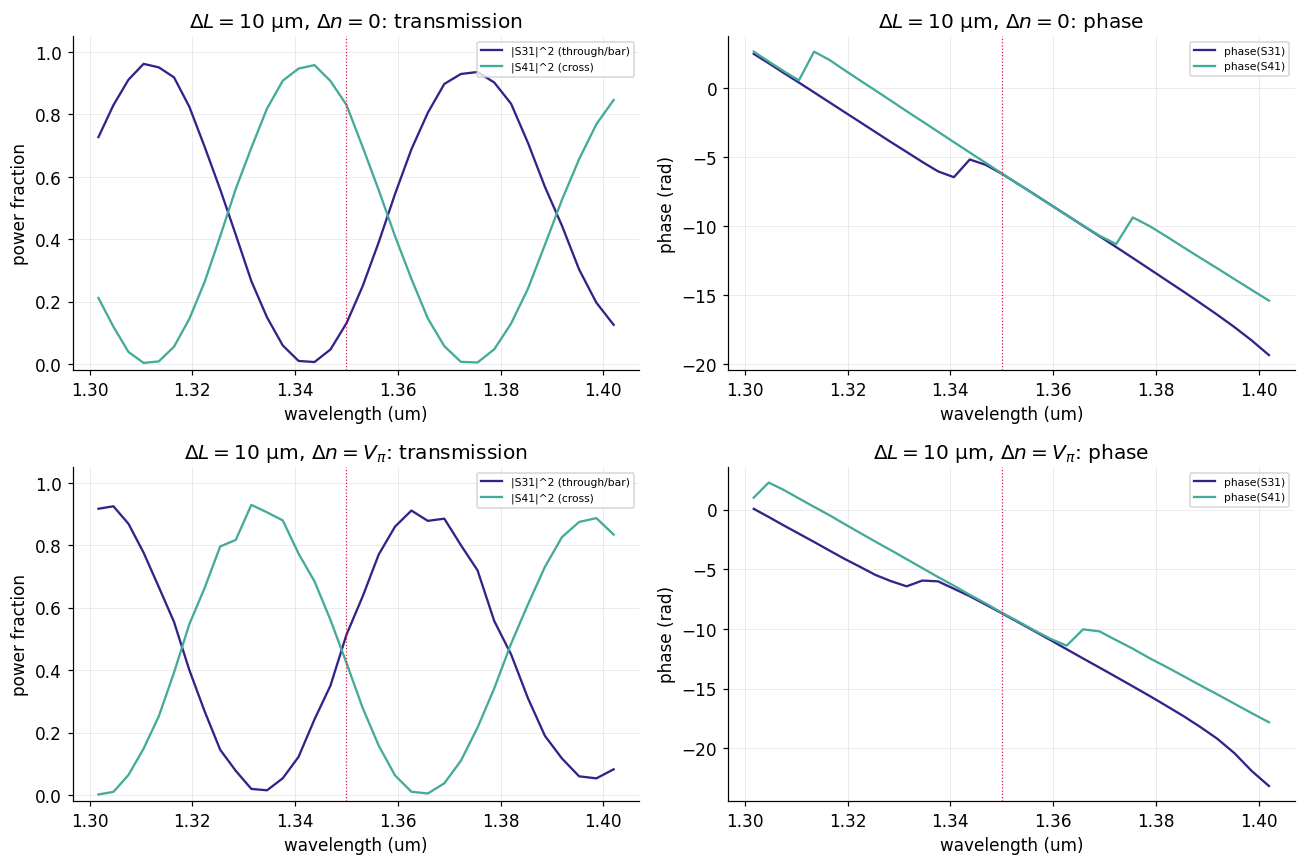

delta_L=10.0um: at Delta_n=0 the device favors cross (S41) (S31=0.131, S41=0.830)
delta_L=10.0um: at Delta_n=Vpi the device favors bar (S31) (S31=0.514, S41=0.423)
-> bar/cross swap with the static bias present: YES


In [18]:
# Re-load from disk (cell 32's own saved artifacts) rather than relying on the in-memory
# dl_results dict, so this cell can be re-run standalone without re-running cell 32's FDTD.
DELTA_L_UM = 10.0   # matches cell 32's own setting
dl_off_artifact = mzm.load_artifact(f"../data/sparams/mzm/delta_L/mzm_dL{DELTA_L_UM:.0f}_dn0p0000")
dl_on_artifact = mzm.load_artifact(f"../data/sparams/mzm/delta_L/mzm_dL{DELTA_L_UM:.0f}_dn0p0020")

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
(ax_mag_off, ax_phase_off), (ax_mag_on, ax_phase_on) = axes

for ax_mag, ax_phase, art, label in [
    (ax_mag_off, ax_phase_off, dl_off_artifact, r"$\Delta n=0$"),
    (ax_mag_on, ax_phase_on, dl_on_artifact, r"$\Delta n=V_\pi$"),
]:
    wl = art.wavelengths_um
    order = np.argsort(wl)
    wl_s, S31_s, S41_s = wl[order], art.S31[order], art.S41[order]

    ax_mag.plot(wl_s, np.abs(S31_s) ** 2, color=style.COLOR_CYCLE[0], label="|S31|^2 (through/bar)")
    ax_mag.plot(wl_s, np.abs(S41_s) ** 2, color=style.COLOR_CYCLE[2], label="|S41|^2 (cross)")
    ax_mag.axvline(params["wl0_um"], color=style.COLOR_ANNOTATION, lw=0.8, ls=":")
    ax_mag.set_xlabel("wavelength (um)"); ax_mag.set_ylabel("power fraction"); ax_mag.set_ylim(-0.02, 1.05)
    ax_mag.set_title(rf"$\Delta L={DELTA_L_UM:.0f}\ \mathrm{{\mu m}}$, {label}: transmission")
    ax_mag.legend(fontsize=7)

    ax_phase.plot(wl_s, np.unwrap(np.angle(S31_s)), color=style.COLOR_CYCLE[0], label="phase(S31)")
    ax_phase.plot(wl_s, np.unwrap(np.angle(S41_s)), color=style.COLOR_CYCLE[2], label="phase(S41)")
    ax_phase.axvline(params["wl0_um"], color=style.COLOR_ANNOTATION, lw=0.8, ls=":")
    ax_phase.set_xlabel("wavelength (um)"); ax_phase.set_ylabel("phase (rad)")
    ax_phase.set_title(rf"$\Delta L={DELTA_L_UM:.0f}\ \mathrm{{\mu m}}$, {label}: phase")
    ax_phase.legend(fontsize=7)

fig.tight_layout()
plt.show()

i0_off = np.argmin(np.abs(dl_off_artifact.wavelengths_um - params["wl0_um"]))
i0_on = np.argmin(np.abs(dl_on_artifact.wavelengths_um - params["wl0_um"]))
S31_off, S41_off = np.abs(dl_off_artifact.S31[i0_off]) ** 2, np.abs(dl_off_artifact.S41[i0_off]) ** 2
S31_on, S41_on = np.abs(dl_on_artifact.S31[i0_on]) ** 2, np.abs(dl_on_artifact.S41[i0_on]) ** 2

dominant_off = "bar (S31)" if S31_off > S41_off else "cross (S41)"
dominant_on = "bar (S31)" if S31_on > S41_on else "cross (S41)"
print(f"delta_L={DELTA_L_UM}um: at Delta_n=0 the device favors {dominant_off} (S31={S31_off:.3f}, S41={S41_off:.3f})")
print(f"delta_L={DELTA_L_UM}um: at Delta_n=Vpi the device favors {dominant_on} (S31={S31_on:.3f}, S41={S41_on:.3f})")
print(f"-> bar/cross swap with the static bias present: {'YES' if dominant_off != dominant_on else 'NO'}")


## 12. Save design point

In [19]:
design_point_path = "../data/design_points/mzm.yaml"
design_points.save_design_point(design_point_path, {
    "component": "mzm",
    "parameters": {k: params[k] for k in [
        "coupling_length_um", "gap_um", "wg_width_um", "wg_height_um", "core_index", "clad_index",
        "sbend_len_um", "wide_sep_um", "delta_n_vpi", "sigma_um", "margin_sigma",
    ]},
    "arm_length_um": ARM_LENGTH_UM, "plateau_length_um": PLATEAU_LENGTH_UM,
    "phase_factor_prior": params["phase_factor_prior"], "phase_factor_measured": float(PHASE_FACTOR_MEASURED),
    "dphi_meep_at_vpi_pi": float(DPHI_MEEP_VPI / np.pi),
    "source_artifact": "si/data/sparams/mzm/baseline/mzm_baseline",
    "provenance": {
        "method": "vpi_defined_arm_length_derivation",
        "date": result.sim_params["creation_date"],
        "meep_version": result.sim_params["meep_version"],
    },
    "validation": validation,
    "rationale": (
        "Delta_n_vpi=0.002 is an explicitly chosen design target (push-pull, n_upper/n_lower = "
        "core_index +/- Delta_n/2), not a value found by sweep-and-select. The arm length is "
        "derived from this target via an idealized formula corrected by phase_factor_prior "
        "(an earlier embedded-device calibration at a 10x larger push-pull differential), then "
        "checked by FDTD (si/notebooks/08_mzm.ipynb Section 10): the phase swing at Delta_n_vpi is "
        f"{DPHI_MEEP_VPI/np.pi:.3f} pi against a 1.000 pi target, read from the normalized "
        "output split with the branch set by the sign of S31/S41. "
        "phase_factor_prior is an effective phase-response factor, not a 0<=Gamma<=1 "
        "mode-confinement factor -- see mzm.py's own DEFAULT_PARAMS comment for why it is "
        "allowed to exceed 1. Edit this rationale directly if a different Delta_n_vpi or "
        "phase_factor_prior is preferred."
    ),
})
print("saved:", design_point_path)


saved: ../data/design_points/mzm.yaml


## 13. MZM SAX model

Not exercised in this notebook -- `models/mzm.py` must work in a process
where `meep` was never imported, so its own correctness is checked
separately, not here.

In [20]:
with open("../../src/pic_toolkit/models/mzm.py") as f:
    print(f.read())


"""SAX-compatible component model for the Mach-Zehnder Modulator.

Architectural rule: this file NEVER imports meep, and NEVER launches an FDTD
simulation -- same rule as models/mzi.py, models/coupler.py, etc. It reads
the cached, validated artifact that si/notebooks/08_mzm.ipynb already produced
at the Vpi push-pull-ON operating point, via the design point that names it.

It returns the complex FDTD S-parameters (magnitude and phase), the same
convention as models/coupler.py and models/mzi.py.

This model exposes ONE fixed operating point (the cached Vpi-ON baseline);
it does not interpolate across Delta_n the way a real voltage-driven device
would need to. A Delta_n-dependent circuit model is future work -- see
si/notebooks/08_mzm.ipynb Section 9's Delta_n sweep for the underlying
Meep-measured data this would be built from.
"""

from __future__ import annotations

import json
import sys
from pathlib import Path

import numpy as np

from .. import design_points

assert "meep" not in 

## 14. Summary

The push-pull MZM switches cleanly: with identical arms all power crosses
($|S_{41}|^2 = 0.988$, bar below $10^{-4}$), and at $\Delta n_{V_\pi}$ it reaches the bar port
($|S_{31}|^2 = 0.983$). The differential phase read from the outputs (Section 10) grows
linearly with $\Delta n$ and reaches **1.042π** at $\Delta n_{V_\pi}$, slightly past the π
target: the measured phase-response factor is $\Gamma_\mathrm{eff} = 1.063$ (constant to
0.6 % across the sweep), against the prior 1.02 used to size the 331 µm plateau. With a
10 µm static path difference the same drive still swaps bar and cross (Section 11). The
design point (`si/data/design_points/mzm.yaml`) and the artifacts under `si/data/sparams/mzm/`
record these numbers; `models/mzm.py` serves the $V_\pi$-ON baseline as a meep-free SAX
component.

**Limitations**
1. `phase_factor_prior` is reused from a different $\Delta n$ regime (a 10x larger push-pull
   differential); it is an effective phase-response factor, not a $0\le\Gamma\le1$
   mode-confinement factor (which is why it is allowed to exceed 1 -- see `mzm.py`'s
   `DEFAULT_PARAMS` comment). A slab mode-solver perturbation estimate gives
   $\partial n_\mathrm{eff}/\partial n_\mathrm{core} \approx 1.03$; the remaining few-percent
   difference to the measured 1.063 is not explained here.
2. The device runs at `resolution=25` with the coupler length that was 50:50 for the coupler
   characterization it was set up with (13.848 µm), coarser than the resolution 40 used for
   the standalone coupler and MZI (Section 1).
3. The $\Delta n$ sweep (Section 9) and $\Delta L$ check (Section 11) use single-excitation
   `simulate()`, not the dual-excitation `simulate_baseline()` -- no reciprocity check at
   those points, only at the one canonical baseline.
4. As in every earlier notebook in this series, the electrical
   (voltage $\to$ carrier density $\to$ $\Delta n$) mechanism is not modeled.
5. `models/mzm.py` exposes one fixed operating point (the cached $V_\pi$-ON baseline) rather
   than a $\Delta n$-dependent circuit model.